### Constraints
- Predict the age of the abalone with accuracy of +/- 3 years for 90% of predictions
- Limit Size & Memory

### Roles
- Tree Ensembles: Alia
- Knn: Yaqoub
- SVR: Alasdair 
- Validation & Pipeline: Mrugaya
- Benchmarking & Testing: Rayan


In [53]:
import os
import argparse
import csv
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ai4_tools as ai4
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, train_test_split, RandomizedSearchCV, cross_validate, validation_curve
from sklearn.metrics import make_scorer,  mean_squared_error, root_mean_squared_error
from sklearn.datasets import make_regression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_selection import SelectKBest, f_regression

warnings.filterwarnings("ignore", category=UserWarning)
RUNTIME = ai4.show_runtime()

RANDOM_STATE = 42
TEST_SIZE = 0.2
AGE_OFFSET = 1.5
TARGET = "rings"
CATEGORICAL_FEATURES = ["sex"]
NUMERIC_FEATURES = [
    "length",
    "diameter",
    "height",
    "whole_weight",
    "shucked_weight",
    "viscera_weight",
    "shell_weight",
]
def calculate_age(rings):
    """Convert the number of rings to age in years."""
    return rings + AGE_OFFSET

Runtime: Windows | AMD64 Family 25 Model 33 Stepping 0, AuthenticAMD (24 cores, 31.9 GB) | CPU only | Python 3.14.0


In [23]:
# Code from  team member for standardizing the pipeline construction
# 1. PREPROCESSING PIPELINE
# Assuming column 0 is 'Sex' (categorical) and columns 1-8 are 
# the numerical physical measurements of the abalone.
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), [0]),  # Encodes Sex (M, F, I)
        ('num', StandardScaler(), slice(1, 9))                 # Scales measurements
    ]
)

#When you build your model pipelines, plug the preprocessor object at the very beginning of your pipeline 
#before your estimator so that scaling and encoding happen safely inside the CV loop.

# 2. SHARED CROSS-VALIDATION PROTOCOL
# The brief requires every model to use the exact same folds. 
shared_cv = KFold(n_splits=5, shuffle=True, random_state=42) 
#pls use shared_cv for all your cross-validation loops 
#so we are evaluating models on the exact same data splits

# 3. CUSTOM CONSTRAINT METRIC (+/- 3 years for 90% of cases)
def within_tolerance_score(y_true, y_pred):
    """
    Calculates the fraction of predictions that fall within 
    +/- 3 units (years/rings) of the true value.
    """
    abs_errors = np.abs(y_true - y_pred)
    fraction_within = np.mean(abs_errors <= 3.0)
    return fraction_within

constraint_scorer = make_scorer(within_tolerance_score, greater_is_better=True)

In [44]:
# Load the data from the CSV file and preprocess it
data = pd.read_csv("abalone.csv")
x = data.drop(columns=[TARGET])
y = data[TARGET]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('svr', SVR(kernel='rbf'))])

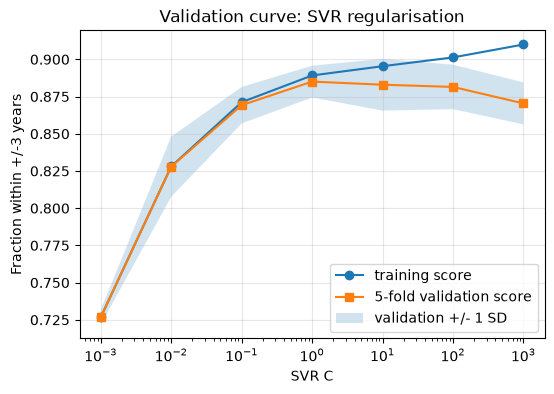

In [45]:
c_values = np.logspace(-3, 3, 7)
train_scores, validation_scores = validation_curve(
    pipeline,
    x_train,
    y_train,
    param_name="svr__C",
    param_range=c_values,
    cv=shared_cv,
    scoring=constraint_scorer,
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(c_values, train_mean, "o-", label="training score")
ax.plot(c_values, validation_mean, "s-", label="5-fold validation score")
ax.fill_between(
    c_values,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.2,
    label="validation +/- 1 SD",
)
ax.set_xscale("log")
ax.set_xlabel("SVR C")
ax.set_ylabel("Fraction within +/-3 years")
ax.set_title("Validation curve: SVR regularisation")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [49]:
parameter_grid = {
        "svr__C": np.logspace(1, 3, 4),         
        "svr__gamma": np.logspace(-3, 1, 5),     
        "svr__epsilon": [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0],
    }
search = GridSearchCV(pipeline, parameter_grid, scoring={'constraint_scorer': constraint_scorer, 'neg_mean_squared_error': make_scorer(mean_squared_error, greater_is_better=False)}, refit='constraint_scorer', cv=shared_cv, n_jobs=-1, return_train_score=True)
search.fit(x_train, y_train)
svr_metrics = ai4.benchmark(model=search.best_estimator_, X_train=x_train, y_train=y_train, X_test=x_test, y_test=y_test, scorer=within_tolerance_score, label="Tuned SVR Pipeline", measure_memory=True)
table = ai4.ResultsTable()
table.add("SVR", svr_metrics)
display(table.df())
vector_number = search.best_estimator_.named_steps["svr"].n_support_[0]
print(f"Number of support vectors: {vector_number}")

,model,score,fit_s,predict_ms_per_1k,fit_s_best,predict_s,n_train,n_test,repeats,peak_mem_mb,mem_metric
0,SVR,0.87799,0.236136,48.894258,0.235811,0.040876,3341,836,3,0.296875,host process RSS (peak minus baseline)


Number of support vectors: 1176


In [50]:
print("Best hyperparameters:")
for parameter, value in search.best_params_.items():
    print(f"{parameter}: {value}")

Best hyperparameters:
svr__C: 1000.0
svr__epsilon: 1.5
svr__gamma: 0.01


C:\Users\alasd\AppData\Local\Temp\ipykernel_29800\919886362.py:19: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


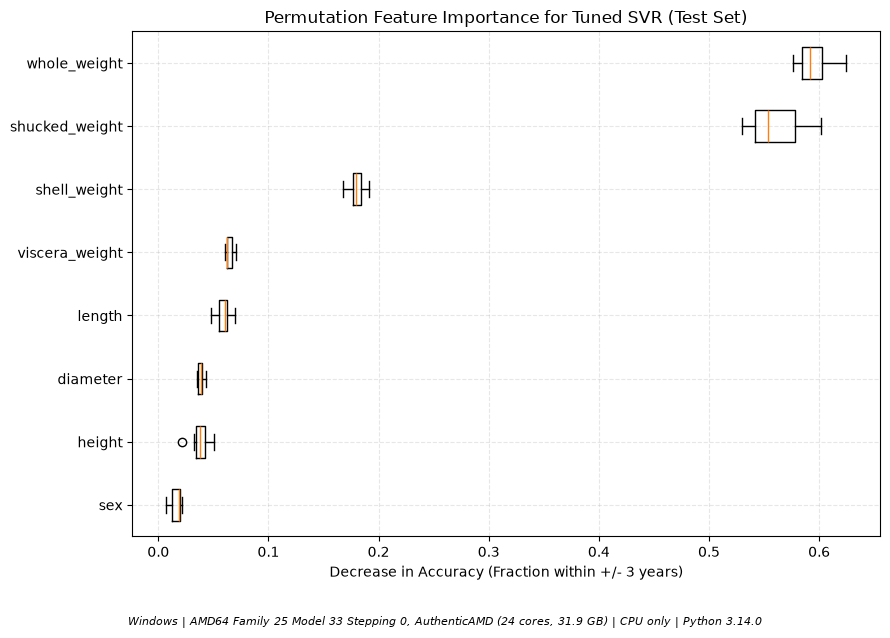

In [55]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    search.best_estimator_, 
    x_test, 
    y_test, 
    scoring=constraint_scorer, 
    n_repeats=10, 
    random_state=RANDOM_STATE, 
    n_jobs=-1
)

feature_names = x_test.columns.to_numpy()
sorted_idx = perm_importance.importances_mean.argsort()

sorted_idx = perm_importance.importances_mean.argsort()

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(
    perm_importance.importances[sorted_idx].T,
    vert=False,
    tick_labels=feature_names[sorted_idx]
)
ax.set_xlabel("Decrease in Accuracy (Fraction within +/- 3 years)")
ax.set_title("Permutation Feature Importance for Tuned SVR (Test Set)")
ax.grid(alpha=0.3, linestyle="--")

fig.text(0.5, -0.05, ai4.runtime_line(), ha="center", fontsize=8, style="italic")
plt.tight_layout()
plt.show()